<a href="https://colab.research.google.com/github/eparks8/ECGR-5105-Intro-to-ML/blob/main/HW6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Homework 6: Fully Connected Neural Networks

### Libraries

In [ ]:
# Data Manipulation
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

# Model
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.svm import SVR
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, precision_score, recall_score, f1_score

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Google Drive Imports
from google.colab import drive

### Data

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df_housing = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Datasets/Housing.csv")
df_cancer = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Datasets/Cancer.csv")

## Problem 1: Housing Price Prediction

### Model Setup

In [ ]:
def training_loop(n_epochs, optimizer, model, loss_fn, t_u_train, t_u_val, t_c_train, t_c_val):
    history = {'train_loss': [], 'val_loss': []}
    for epoch in range(1, n_epochs + 1):
        model.train()
        t_p_train = model(t_u_train)
        loss_train = loss_fn(t_p_train, t_c_train)

        model.eval()
        with torch.no_grad():
            t_p_val = model(t_u_val)
            loss_val = loss_fn(t_p_val, t_c_val)

        optimizer.zero_grad()
        loss_train.backward()
        optimizer.step()

        history['train_loss'].append(loss_train.item())
        history['val_loss'].append(loss_val.item())

    return history

In [ ]:
model = nn.Sequential(
    nn.Linear(12, 25),
    nn.ReLU(),
    nn.Linear(25, 50),
    nn.ReLU(),
    nn.Linear(50, 25),
    nn.ReLU(),
    nn.Linear(25, 10),
    nn.ReLU(),
    nn.Linear(10, 1)
)

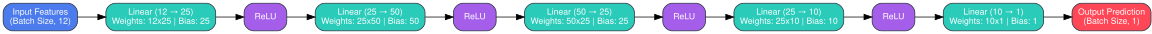

In [ ]:
import graphviz

# Create a simplified Netron-like visual block diagram
dot = graphviz.Digraph(comment='Simplified FCNN Architecture', format='png')
dot.attr(rankdir='LR', size='16,8')
dot.attr('node', shape='box', style='filled,rounded', color='#2F3542', fontname='Helvetica', fontsize='11', fontcolor='white')

# Define nodes mirroring Netron blocks
dot.node('input', 'Input Features\n(Batch Size, 12)', fillcolor='#4B7BEC')

dot.node('linear1', 'Linear (12 → 25)\nWeights: 12x25 | Bias: 25', fillcolor='#2bcbba')
dot.node('relu1', 'ReLU', fillcolor='#a55eea')

dot.node('linear2', 'Linear (25 → 50)\nWeights: 25x50 | Bias: 50', fillcolor='#2bcbba')
dot.node('relu2', 'ReLU', fillcolor='#a55eea')

dot.node('linear3', 'Linear (50 → 25)\nWeights: 50x25 | Bias: 25', fillcolor='#2bcbba')
dot.node('relu3', 'ReLU', fillcolor='#a55eea')

dot.node('linear4', 'Linear (25 → 10)\nWeights: 25x10 | Bias: 10', fillcolor='#2bcbba')
dot.node('relu4', 'ReLU', fillcolor='#a55eea')

dot.node('linear5', 'Linear (10 → 1)\nWeights: 10x1 | Bias: 1', fillcolor='#2bcbba')

dot.node('output', 'Output Prediction\n(Batch Size, 1)', fillcolor='#ff4757')

# Define connections
dot.edge('input', 'linear1')
dot.edge('linear1', 'relu1')
dot.edge('relu1', 'linear2')
dot.edge('linear2', 'relu2')
dot.edge('relu2', 'linear3')

dot.edge('linear3', 'relu3')
dot.edge('relu3', 'linear4')
dot.edge('linear4', 'relu4')

dot.edge('relu4', 'linear5')
dot.edge('linear5', 'output')

dot.view()

dot

### Data Preprocessing

In [ ]:
binary_cols = ['mainroad','guestroom','basement','hotwaterheating','airconditioning','prefarea']
binary_map = {'yes': 1, 'no': 0}

furnishings = ['furnished', 'semi-furnished', 'unfurnished']
furnishing_map = {'furnished': 2, 'semi-furnished': 1, 'unfurnished': 0}

df_housing[binary_cols] = df_housing[binary_cols].replace(binary_map)
df_housing['furnishingstatus'] = df_housing['furnishingstatus'].replace(furnishing_map)
df_housing_clean = df_housing.dropna(subset=binary_cols + ['area', 'bedrooms', 'bathrooms', 'stories', 'price'])

# 80/20 split, standardization
X_train, X_test, y_train, y_test = train_test_split(df_housing.drop("price", axis=1), df_housing["price"], test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Training

In [ ]:
optimizer = optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

# Scale targets to stabilize training
y_train_scaled_price = y_train.values / 1e6
y_test_scaled_price = y_test.values / 1e6

housing_history = training_loop(
    n_epochs = 500,
    optimizer = optimizer,
    model = model,
    loss_fn = loss_fn,
    t_u_train = torch.tensor(X_train, dtype=torch.float32),
    t_u_val = torch.tensor(X_test, dtype=torch.float32),
    # Unsqueeze targets to match the [N, 1] shape of the model output
    t_c_train = torch.tensor(y_train_scaled_price, dtype=torch.float32).unsqueeze(1),
    t_c_val = torch.tensor(y_test_scaled_price, dtype=torch.float32).unsqueeze(1)
)

### Plotting

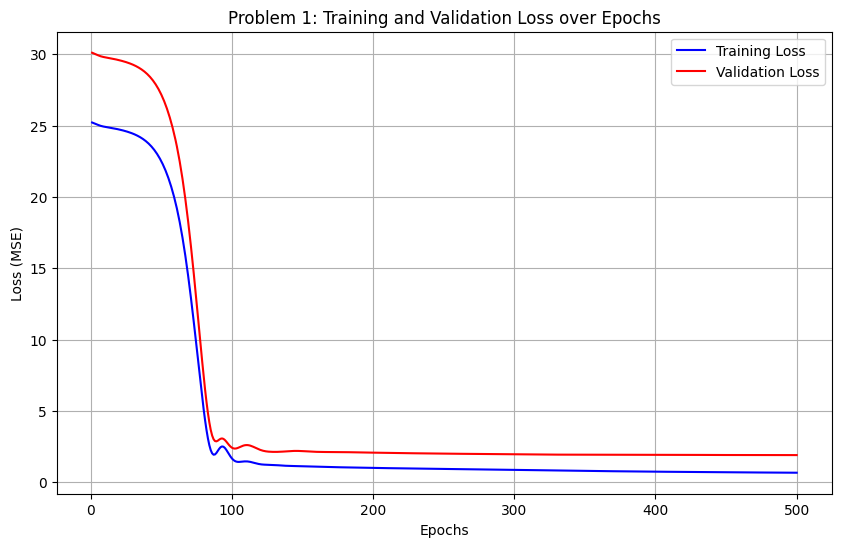

In [ ]:
# Plot the training and validation losses over epochs
plt.figure(figsize=(10, 6))
plt.plot(range(1, 501), housing_history['train_loss'], label='Training Loss', color='blue')
plt.plot(range(1, 501), housing_history['val_loss'], label='Validation Loss', color='red')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.title('Problem 1: Training and Validation Loss over Epochs')
plt.legend()
plt.grid(True)
plt.show()

### Comparison
Compare against traditional Linear Regression and SVR.

#### Linear Model

In [ ]:
lin_model = nn.Linear(12, 1)
# Increase the learning rate to 0.001 for faster, stable convergence
optimizer = optim.SGD(lin_model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

# Increase epochs to 5000 to allow the SGD optimizer to fully converge
lin_history = training_loop(
    n_epochs = 5000,
    optimizer = optimizer,
    model = lin_model,
    loss_fn = loss_fn,
    t_u_train = torch.tensor(X_train, dtype=torch.float32),
    t_u_val = torch.tensor(X_test, dtype=torch.float32),
    t_c_train = torch.tensor(y_train_scaled_price, dtype=torch.float32).unsqueeze(1),
    t_c_val = torch.tensor(y_test_scaled_price, dtype=torch.float32).unsqueeze(1)
)

#### SVR Model

In [ ]:
svr_model = SVR(kernel='linear', C=1.0, epsilon=0.1)
svr_model.fit(X_train, y_train_scaled_price)

y_train_pred = svr_model.predict(X_train)
y_test_pred = svr_model.predict(X_test)

# Evaluate Mean Squared Error
train_loss = mean_squared_error(y_train_scaled_price, y_train_pred)
val_loss = mean_squared_error(y_test_scaled_price, y_test_pred)

print(f"SVR Training Loss (MSE): {train_loss:.4f}")
print(f"SVR Validation Loss (MSE): {val_loss:.4f}")

SVR Training Loss (MSE): 0.9966
SVR Validation Loss (MSE): 1.8994


#### Metrics

In [ ]:
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

# Fully Connected Neural Network
model.eval()
with torch.no_grad():
    y_pred_nn = model(X_test_tensor).numpy().flatten()

# Linear Regression Model
lin_model.eval()
with torch.no_grad():
    y_pred_lin = lin_model(X_test_tensor).numpy().flatten()

# SVR Model
y_pred_svr = svr_model.predict(X_test)

# Target variable
y_true = y_test_scaled_price

# Calculate metrics (MSE, RMSE, R²)
metrics = {
    "Model": ["Neural Network (FCNN)", "Linear Regression (PyTorch SGD)", "SVR (Linear Kernel)"],
    "MSE": [
        mean_squared_error(y_true, y_pred_nn),
        mean_squared_error(y_true, y_pred_lin),
        mean_squared_error(y_true, y_pred_svr)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_true, y_pred_nn)),
        np.sqrt(mean_squared_error(y_true, y_pred_lin)),
        np.sqrt(mean_squared_error(y_true, y_pred_svr))
    ],
    "R² Score": [
        r2_score(y_true, y_pred_nn),
        r2_score(y_true, y_pred_lin),
        r2_score(y_true, y_pred_svr)
    ]
}

df_comparison = pd.DataFrame(metrics)
display(df_comparison)

,Model,MSE,RMSE,R² Score
0,Neural Network (FCNN),1.901775,1.379049,0.623751
1,Linear Regression (PyTorch SGD),1.771171,1.330854,0.649590
2,SVR (Linear Kernel),1.899382,1.378181,0.624225


## Problem 2: Breast Cancer Classifier

### Model Setup

In [ ]:
def training_loop_classifier(n_epochs, optimizer, model, loss_fn, t_u_train, t_u_val, t_c_train, t_c_val):
    history = {
        'train_loss': [],
        'val_loss': [],
        'train_acc': [],
        'val_acc': []
    }

    for epoch in range(1, n_epochs + 1):
        model.train()
        t_p_train = model(t_u_train)
        loss_train = loss_fn(t_p_train, t_c_train)

        model.eval()
        with torch.no_grad():
            t_p_val = model(t_u_val)
            loss_val = loss_fn(t_p_val, t_c_val)

            # Calculate accuracies directly
            train_preds = (t_p_train >= 0.5).float()
            val_preds = (t_p_val >= 0.5).float()

            train_acc = (train_preds == t_c_train).float().mean().item()
            val_acc = (val_preds == t_c_val).float().mean().item()

        optimizer.zero_grad()
        loss_train.backward()
        optimizer.step()

        # Save metrics to history
        history['train_loss'].append(loss_train.item())
        history['val_loss'].append(loss_val.item())
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        if epoch == 1 or epoch % 100 == 0:
            print(f"Epoch {epoch}, Training Loss: {loss_train.item():.4f}, Validation Loss: {loss_val.item():.4f}, Train Acc: {train_acc*100:.2f}%, Val Acc: {val_acc*100:.2f}%")

    return history

In [ ]:
classifier = nn.Sequential(
    nn.Linear(30, 100),
    nn.ReLU(),
    nn.Linear(100, 100),
    nn.ReLU(),
    nn.Linear(100, 1),
    nn.Sigmoid()
)

### Data Preprocessing

In [ ]:
Xc_train, Xc_val, Yc_train, Yc_val = train_test_split(df_cancer.drop(columns=['diagnosis', 'id']), df_cancer['diagnosis'], test_size=0.2, random_state=5105)
c_std = StandardScaler()
Xc_train = c_std.fit_transform(Xc_train)
Xc_val = c_std.transform(Xc_val)

### Training

In [ ]:
# Convert 'M' and 'B' diagnoses to binary numbers (1.0 for Malignant, 0.0 for Benign)
y_c_train_binary = (Yc_train.values == 'M').astype(float)
y_c_val_binary = (Yc_val.values == 'M').astype(float)

# Convert numpy arrays to PyTorch tensors
t_u_train = torch.tensor(Xc_train, dtype=torch.float32)
t_u_val = torch.tensor(Xc_val, dtype=torch.float32)
t_c_train = torch.tensor(y_c_train_binary, dtype=torch.float32).unsqueeze(1)
t_c_val = torch.tensor(y_c_val_binary, dtype=torch.float32).unsqueeze(1)

# Set up binary classification optimizer and loss function
# Use Adam optimizer as done with the FCNN model previously
optimizer_c = optim.Adam(classifier.parameters(), lr=0.001)
loss_fn_c = nn.BCELoss() # BCELoss matches the Sigmoid output activation in our classifier

# Train the classifier using our custom loop
history = training_loop_classifier(
    n_epochs=1000,
    optimizer=optimizer_c,
    model=classifier,
    loss_fn=loss_fn_c,
    t_u_train=t_u_train,
    t_u_val=t_u_val,
    t_c_train=t_c_train,
    t_c_val=t_c_val
)

Epoch 1, Training Loss: 0.6755, Validation Loss: 0.6767, Train Acc: 76.48%, Val Acc: 77.19%
Epoch 100, Training Loss: 0.0338, Validation Loss: 0.0864, Train Acc: 99.34%, Val Acc: 96.49%
Epoch 200, Training Loss: 0.0062, Validation Loss: 0.1415, Train Acc: 100.00%, Val Acc: 97.37%
Epoch 300, Training Loss: 0.0013, Validation Loss: 0.1995, Train Acc: 100.00%, Val Acc: 97.37%
Epoch 400, Training Loss: 0.0005, Validation Loss: 0.2359, Train Acc: 100.00%, Val Acc: 97.37%
Epoch 500, Training Loss: 0.0003, Validation Loss: 0.2585, Train Acc: 100.00%, Val Acc: 97.37%
Epoch 600, Training Loss: 0.0002, Validation Loss: 0.2754, Train Acc: 100.00%, Val Acc: 97.37%
Epoch 700, Training Loss: 0.0001, Validation Loss: 0.2888, Train Acc: 100.00%, Val Acc: 97.37%
Epoch 800, Training Loss: 0.0001, Validation Loss: 0.3003, Train Acc: 100.00%, Val Acc: 97.37%
Epoch 900, Training Loss: 0.0001, Validation Loss: 0.3101, Train Acc: 100.00%, Val Acc: 97.37%
Epoch 1000, Training Loss: 0.0001, Validation Loss: 0.

### Plotting

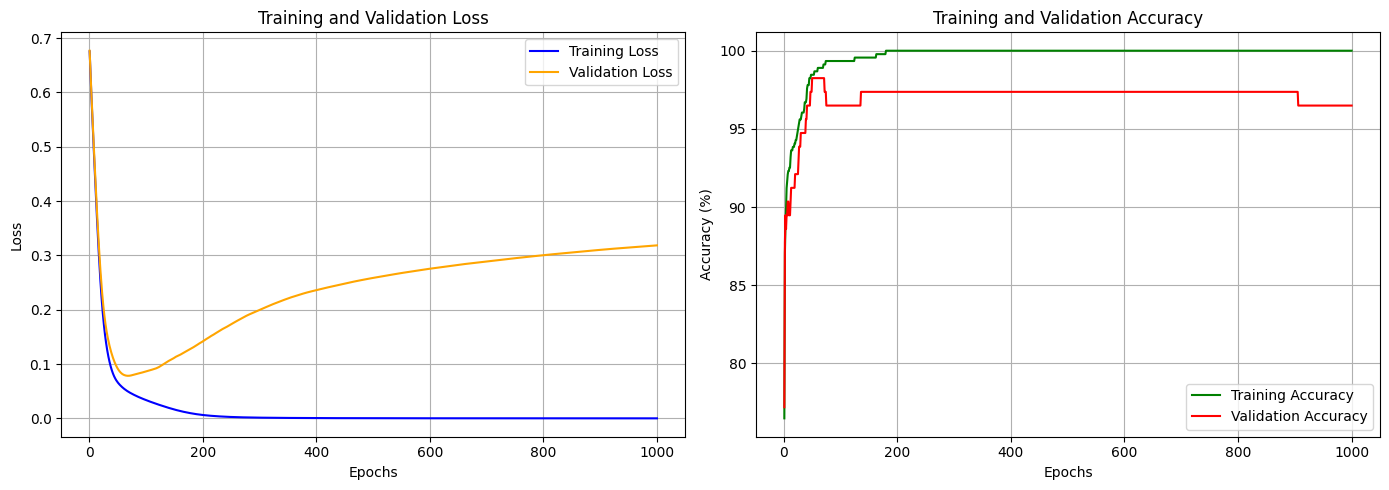

In [ ]:
epochs_range = range(1, 1001)

plt.figure(figsize=(14, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Training Loss', color='blue')
plt.plot(epochs_range, history['val_loss'], label='Validation Loss', color='orange')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, [acc * 100 for acc in history['train_acc']], label='Training Accuracy', color='green')
plt.plot(epochs_range, [acc * 100 for acc in history['val_acc']], label='Validation Accuracy', color='red')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Comparison

In [ ]:
# --- 1. Logistic Regression Model ---
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(Xc_train, y_c_train_binary)
y_pred_log_reg = log_reg.predict(Xc_val)

# --- 2. Support Vector Machine Classifier (SVC) ---
svm_classifier = SVC(kernel='rbf', C=1.0, random_state=42)
svm_classifier.fit(Xc_train, y_c_train_binary)
y_pred_svm = svm_classifier.predict(Xc_val)

# --- 3. Neural Network Classifier Evaluation ---
classifier.eval()
with torch.no_grad():
    t_p_val_nn = classifier(t_u_val)
    y_pred_nn_binary = (t_p_val_nn >= 0.5).float().numpy().flatten()

# True targets for validation set
y_true_c = y_c_val_binary

# Gather metrics
comparison_data = {
    "Model": ["Neural Network (FCNN)", "Logistic Regression", "SVM (RBF Kernel)"],
    "Accuracy": [
        accuracy_score(y_true_c, y_pred_nn_binary),
        accuracy_score(y_true_c, y_pred_log_reg),
        accuracy_score(y_true_c, y_pred_svm)
    ],
    "Precision": [
        precision_score(y_true_c, y_pred_nn_binary, zero_division=0),
        precision_score(y_true_c, y_pred_log_reg, zero_division=0),
        precision_score(y_true_c, y_pred_svm, zero_division=0)
    ],
    "Recall": [
        recall_score(y_true_c, y_pred_nn_binary, zero_division=0),
        recall_score(y_true_c, y_pred_log_reg, zero_division=0),
        recall_score(y_true_c, y_pred_svm, zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_true_c, y_pred_nn_binary, zero_division=0),
        f1_score(y_true_c, y_pred_log_reg, zero_division=0),
        f1_score(y_true_c, y_pred_svm, zero_division=0)
    ]
}

df_classifier_comparison = pd.DataFrame(comparison_data)
display(df_classifier_comparison)

,Model,Accuracy,Precision,Recall,F1-Score
0,Neural Network (FCNN),0.964912,0.955556,0.955556,0.955556
1,Logistic Regression,0.982456,1.000000,0.955556,0.977273
2,SVM (RBF Kernel),0.964912,0.955556,0.955556,0.955556


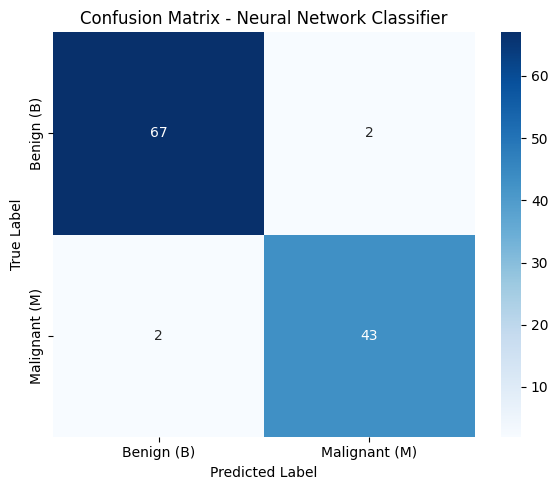

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Compute confusion matrix for the Neural Network Classifier
cm = confusion_matrix(y_true_c, y_pred_nn_binary)

# Plot the heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign (B)', 'Malignant (M)'],
            yticklabels=['Benign (B)', 'Malignant (M)'])
plt.title('Confusion Matrix - Neural Network Classifier')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()